In [1]:
pip install mapof-marriages

  Using cached prefsampling-0.1.24-py3-none-any.whl.metadata (7.4 kB)
  Using cached scikit_learn-1.3.2-cp311-cp311-macosx_12_0_arm64.whl.metadata (11 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 6.1 MB/s  0:00:01eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 27.4 MB/s  0:00:00 eta 0:00:01
Using cached prefsampling-0.1.24-py3-none-any.whl (94 kB)
Using cached scikit_learn-1.3.2-cp311-cp311-macosx_12_0_arm64.whl (9.4 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 24.4 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: gurobipy
    Found existing installation: gurobipy 10.0.3
    Uninstalling gurobipy-10.0.3:
      Successfully uninstalled gurobipy-10.0.3
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.66.6
    Uninstalling tqdm-4.66.6:
      Successfully uninstalled tqdm-4.66.6
  Attempting uninstall: numpy
    Found existing installation: numpy 1.24.4
    Uninstalling numpy-1.24.4:
      Successfully uninstalled n

In [42]:
import mapof.marriages as mapof

In [23]:
experiment = mapof.prepare_offline_marriages_experiment(
                        experiment_id='name_of_the_experiment')

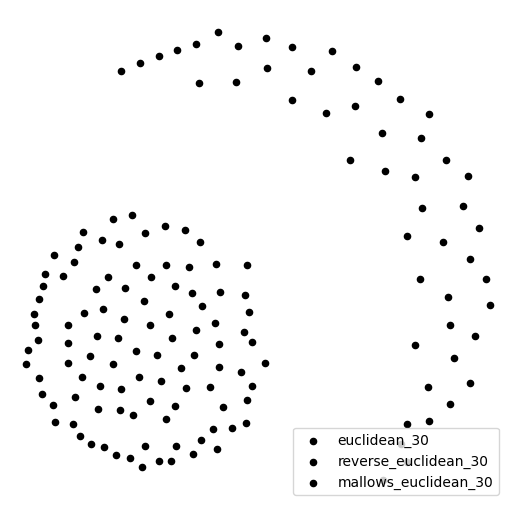

In [1]:
import mapof.marriages as mapof
def demo_workflow():
    experiment = mapof.prepare_online_marriages_experiment()
    experiment.add_family(culture_id='euclidean', size=50, num_agents=30)
    experiment.add_family(culture_id='reverse_euclidean', size=50, num_agents=30)
    experiment.add_family(culture_id='mallows_euclidean', size=50, num_agents=30)
    experiment.compute_distances(distance_id='l1-mutual_attraction')
    experiment.embed_2d(embedding_id='kk')
    experiment.print_map_2d()
if __name__=="__main__":
    demo_workflow()

In [43]:
import os
import csv
import ast
from mapof.marriages import prepare_offline_marriages_experiment

NUM_AGENTS = 30  # 30 men, 30 women

# Ensure folder structure
def ensure_dirs(experiment_id):
    base = os.path.join("experiments", experiment_id, "instances")
    os.makedirs(base, exist_ok=True)
    return base

# Write a single .mi file
def write_mi_file(path, mpref, wpref, culture_id="csv", params=None):
    if params is None:
        params = {}

    with open(path, 'w') as f:
        # First line: culture + params
        f.write(f"# {culture_id} {params}\n")

        # Men block
        f.write(f"{NUM_AGENTS}\n")
        for _ in range(NUM_AGENTS):
            f.write("ignored\n")
        f.write(f"{NUM_AGENTS},,{NUM_AGENTS}\n")
        for i, ranking in enumerate(mpref):
            # Convert to 0-indexed if needed
            ranking_0 = [x-1 if x > 0 else x for x in ranking]
            f.write(f"{i}," + ",".join(map(str, ranking_0)) + "\n")

        # Women block
        f.write(f"{NUM_AGENTS}\n")
        for _ in range(NUM_AGENTS):
            f.write("ignored\n")
        f.write(f"{NUM_AGENTS},,{NUM_AGENTS}\n")
        for i, ranking in enumerate(wpref):
            ranking_0 = [x-1 if x > 0 else x for x in ranking]
            f.write(f"{i}," + ",".join(map(str, ranking_0)) + "\n")

# Convert CSV to MAPOF .mi files
def convert_csv_to_mi(csv_path, experiment_id="csv_experiment"):
    base = ensure_dirs(experiment_id)

    with open(csv_path, newline='') as f:
        reader = csv.DictReader(f)
        for idx, row in enumerate(reader):
            # Safely parse the string lists
            mpref = ast.literal_eval(row["mpref"])
            wpref = ast.literal_eval(row["wpref"])

            if len(mpref) != NUM_AGENTS or len(wpref) != NUM_AGENTS:
                raise ValueError(f"Row {idx} does not have {NUM_AGENTS} men/women rankings.")

            # Output path
            instance_id = f"inst_{idx}"
            outpath = os.path.join(base, f"{instance_id}.mi")

            write_mi_file(outpath, mpref, wpref)
            print("Wrote", outpath)

    print("All instances written successfully!")

def run_map(experiment_id="csv_experiment"):
    exp = prepare_offline_marriages_experiment(experiment_id=experiment_id)

    # Load instances from .mi files
    exp.prepare_instances()

    # Ensure we actually have instances
    print("Number of instances:", len(exp.instances))
    if len(exp.instances) == 0:
        raise RuntimeError("No instances loaded! Check your .mi files.")

    # Compute distances
    exp.compute_distances(distance_id="l1-mutual_attraction")

    # Compute features
    exp.compute_feature(feature_id="summed_rank_minimal_matching")

    for inst in exp.instances:
        print(inst.id, inst.features.keys())

    # Embed into 2D
    exp.embed_2d(embedding_id="kk")

    # Save or show map
    exp.print_map_2d(show=True)


In [44]:
# Convert CSV to .mi files
convert_csv_to_mi("reverse_euclidean_accomplice.csv")

# Then run your MAPOF map
run_map("csv_experiment")


Wrote experiments/csv_experiment/instances/inst_0.mi
Wrote experiments/csv_experiment/instances/inst_1.mi
Wrote experiments/csv_experiment/instances/inst_2.mi
Wrote experiments/csv_experiment/instances/inst_3.mi
Wrote experiments/csv_experiment/instances/inst_4.mi
Wrote experiments/csv_experiment/instances/inst_5.mi
Wrote experiments/csv_experiment/instances/inst_6.mi
Wrote experiments/csv_experiment/instances/inst_7.mi
Wrote experiments/csv_experiment/instances/inst_8.mi
Wrote experiments/csv_experiment/instances/inst_9.mi
Wrote experiments/csv_experiment/instances/inst_10.mi
Wrote experiments/csv_experiment/instances/inst_11.mi
Wrote experiments/csv_experiment/instances/inst_12.mi
Wrote experiments/csv_experiment/instances/inst_13.mi
Wrote experiments/csv_experiment/instances/inst_14.mi
Wrote experiments/csv_experiment/instances/inst_15.mi
Wrote experiments/csv_experiment/instances/inst_16.mi
Wrote experiments/csv_experiment/instances/inst_17.mi
Wrote experiments/csv_experiment/insta

Preparing instances: 0it [00:00, ?it/s]

Number of instances: 0


RuntimeError: No instances loaded! Check your .mi files.